## 1. Chargement des données

In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from dotenv import load_dotenv

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

load_dotenv()
sns.set_theme(style="whitegrid")

MONGO_URI = os.getenv("MONGO_URI")
client = MongoClient(MONGO_URI)
db = client["smartmovie"]

df_features = pd.DataFrame(list(db["movies_features"].find({}, {"_id": 0})))
df_text = pd.DataFrame(list(db["movies"].find({}, {"_id": 0, "movie_id": 1, "overview": 1})))

df = df_features.merge(df_text, on="movie_id", how="left")
print(f"{len(df)} films chargés")
df.head()


931 films chargés


,movie_id,budget,budget_category,has_keywords,is_holiday_release,is_original_language_en,is_summer_release,n_genres,n_keywords,overview_length,...,release_decade,release_month,release_year,revenue,runtime,runtime_category,title,vote_average,vote_count,overview
0,969681,225000000.0,Très élevé,1,0,1,0,3,19,68,...,1970,1,1970,2.495683e+09,145.0,Long (120-150min),Spider-Man: Brand New Day,7.865,2923,Fighting crime full-time as Spider-Man in a wo...
1,1423191,75000000.0,Élevé,1,0,1,0,3,11,19,...,1970,1,1970,1.964762e+08,95.0,Standard (90-120min),Resident Evil,7.300,556,Medical courier Bryan unwittingly finds himsel...
2,1368337,250000000.0,Très élevé,1,0,1,0,3,19,46,...,1970,1,1970,1.751248e+09,173.0,Très long (>150min),The Odyssey,8.019,3946,"Odysseus, the legendary King of Ithaca, embark..."
3,1751701,100000.0,Faible,1,0,1,0,3,7,91,...,1970,1,1970,NaN,95.0,Standard (90-120min),After Impact,6.281,16,"After losing his father, Ethan Nichols inherit..."
4,1084244,250000000.0,Très élevé,1,0,1,0,4,27,39,...,1970,1,1970,1.136476e+09,102.0,Standard (90-120min),Toy Story 5,8.319,2389,When Bonnie receives a Lilypad tablet as a gif...


## 2. Partie A — Clustering sur variables structurées



In [5]:
structured_cols = [
    "release_year", "release_month", "release_decade",
    "is_summer_release", "is_holiday_release",
    "n_genres", "n_keywords", "has_keywords",
    "runtime", "runtime_category",
    "overview_length", "is_original_language_en",
    "budget", "budget_category",
]

X_struct_raw = df[structured_cols]

numeric_features = X_struct_raw.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
categorical_features = X_struct_raw.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor_struct = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

X_struct = preprocessor_struct.fit_transform(X_struct_raw)
X_struct = X_struct.toarray() if hasattr(X_struct, "toarray") else X_struct

print(f"Matrice de features structurées : {X_struct.shape}")


Matrice de features structurées : (931, 20)


C:\Users\oussa\AppData\Local\Temp\ipykernel_26524\2738078861.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_struct_raw.select_dtypes(include=["object", "category"]).columns.tolist()


### 2.2 Test de plusieurs valeurs de K — Silhouette Score


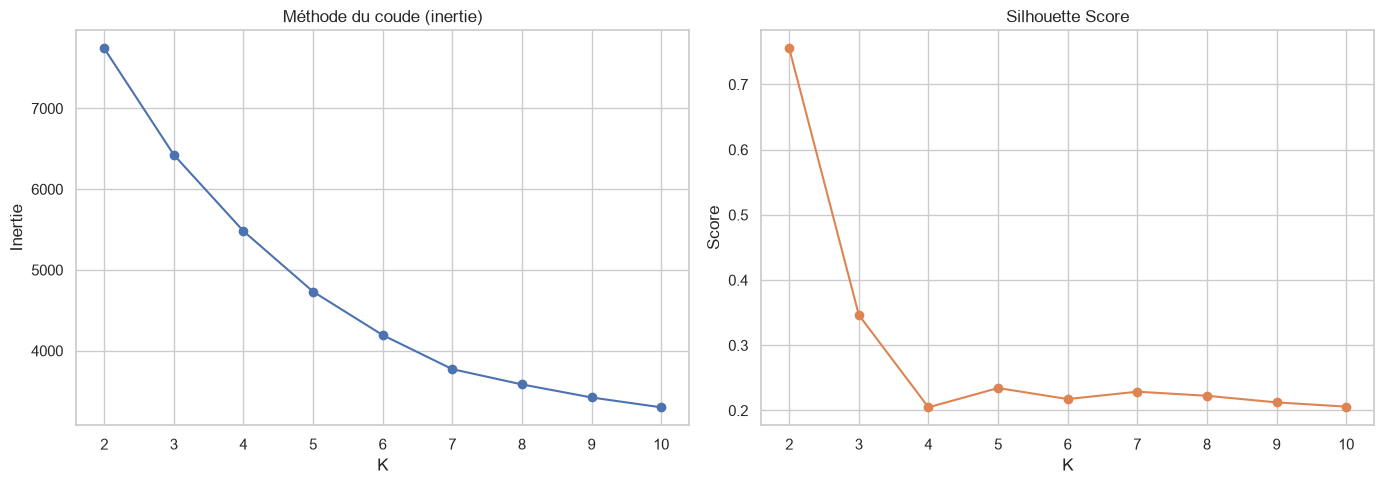

Meilleur K (silhouette) : 2


In [ ]:
k_range = range(2, 11)
inertia_scores = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_struct)
    inertia_scores.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_struct, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertia_scores, marker="o", color="#4C72B0")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertie")

axes[1].plot(list(k_range), silhouette_scores, marker="o", color="#DD8452")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

best_k_struct = list(k_range)[int(np.argmax(silhouette_scores))]
print(f"Meilleur K (silhouette) : {best_k_struct}")


### 2.3 Clustering final et interprétation des clusters

In [7]:
kmeans_struct = KMeans(n_clusters=best_k_struct, random_state=42, n_init=10)
df["cluster_struct"] = kmeans_struct.fit_predict(X_struct)

df["cluster_struct"].value_counts().sort_index()


cluster_struct
0    914
1     17
Name: count, dtype: int64

In [8]:
profile_cols = ["budget", "runtime", "n_genres", "n_keywords", "overview_length",
                 "is_summer_release", "is_holiday_release", "is_original_language_en"]

cluster_profile = df.groupby("cluster_struct")[profile_cols].mean().round(2)
cluster_profile


,budget,runtime,n_genres,n_keywords,overview_length,is_summer_release,is_holiday_release,is_original_language_en
cluster_struct,,,,,,,,
0,90543355.01,116.87,2.79,16.08,45.06,0.0,0.0,0.87
1,3356741.40,120.41,2.65,19.82,42.18,0.0,1.0,0.82


C:\Users\oussa\AppData\Local\Temp\ipykernel_26524\1350474939.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cluster_struct", y="budget", ax=axes[0, 0], palette="Set2")
C:\Users\oussa\AppData\Local\Temp\ipykernel_26524\1350474939.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cluster_struct", y="runtime", ax=axes[0, 1], palette="Set2")


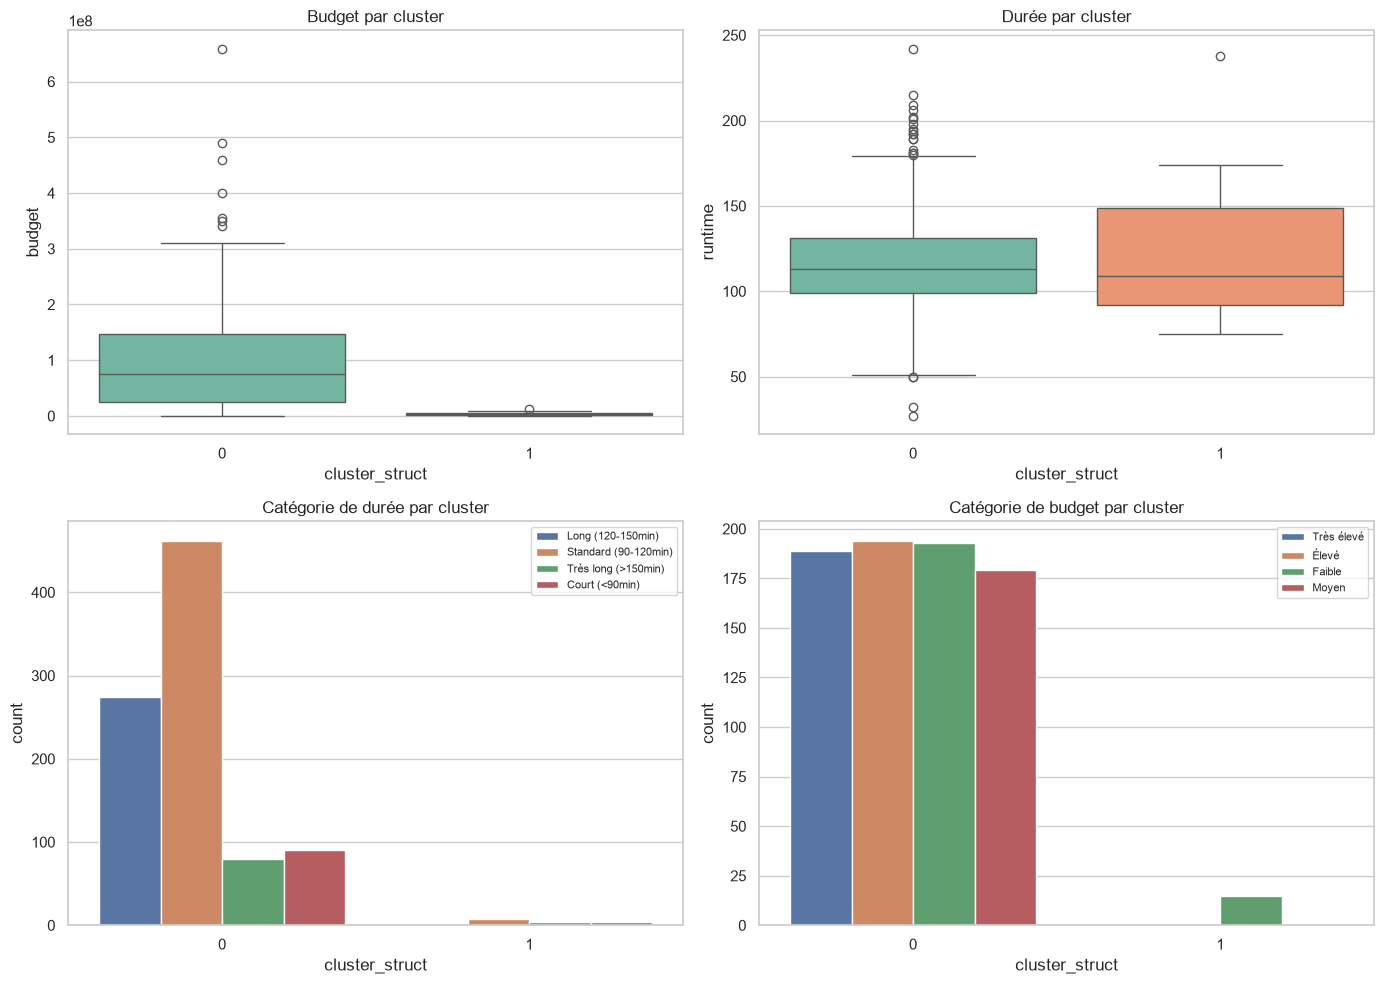

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="cluster_struct", y="budget", ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Budget par cluster")

sns.boxplot(data=df, x="cluster_struct", y="runtime", ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Durée par cluster")

sns.countplot(data=df, x="cluster_struct", hue="runtime_category", ax=axes[1, 0])
axes[1, 0].set_title("Catégorie de durée par cluster")
axes[1, 0].legend(fontsize=8)

sns.countplot(data=df, x="cluster_struct", hue="budget_category", ax=axes[1, 1])
axes[1, 1].set_title("Catégorie de budget par cluster")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()


## 3. Partie B — Clustering sur TF-IDF (`overview`)




In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["overview_clean"] = df["overview"].fillna("").apply(clean_text)

tfidf = TfidfVectorizer(stop_words="english", max_features=1000, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df["overview_clean"])
feature_names = np.array(tfidf.get_feature_names_out())

print(f"Dimensions de la matrice TF-IDF : {X_tfidf.shape}")


Dimensions de la matrice TF-IDF : (931, 1000)


### 3.2 Test de plusieurs valeurs de K — Silhouette Score (distance cosinus)




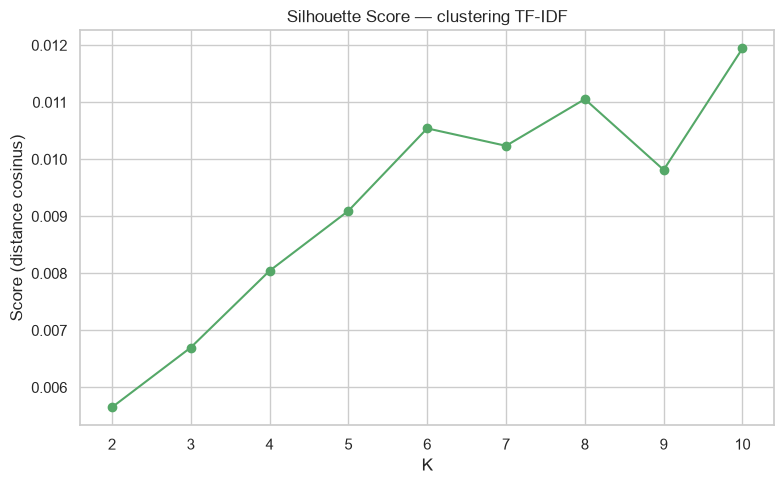

Meilleur K (silhouette, texte) : 10


In [11]:
X_tfidf_dense = X_tfidf.toarray()  # corpus de taille modeste (~1000 docs) : conversion dense acceptable ici

k_range_text = range(2, 11)
silhouette_scores_text = []

for k in k_range_text:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_tfidf_dense)
    silhouette_scores_text.append(silhouette_score(X_tfidf_dense, labels, metric="cosine"))

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_text), silhouette_scores_text, marker="o", color="#55A868")
plt.title("Silhouette Score — clustering TF-IDF")
plt.xlabel("K")
plt.ylabel("Score (distance cosinus)")
plt.tight_layout()
plt.show()

best_k_text = list(k_range_text)[int(np.argmax(silhouette_scores_text))]
print(f"Meilleur K (silhouette, texte) : {best_k_text}")


### 3.3 Clustering final et termes représentatifs par cluster

In [12]:
kmeans_text = KMeans(n_clusters=best_k_text, random_state=42, n_init=10)
df["cluster_text"] = kmeans_text.fit_predict(X_tfidf_dense)

df["cluster_text"].value_counts().sort_index()


cluster_text
0    301
1     85
2     94
3     93
4     62
5     67
6     49
7     79
8     72
9     29
Name: count, dtype: int64

In [13]:
n_top_terms = 10

for cluster_id in range(best_k_text):
    center = kmeans_text.cluster_centers_[cluster_id]
    top_idx = center.argsort()[::-1][:n_top_terms]
    top_terms = feature_names[top_idx]
    print(f"Cluster {cluster_id} ({(df['cluster_text'] == cluster_id).sum()} films) :")
    print("   " + ", ".join(top_terms))
    print()


Cluster 0 (301 films) :
   friends, group, finds, journey, night, turns, town, human, named, mysterious

Cluster 1 (85 films) :
   earth, team, save, mission, planet, world, universe, future, alien, race

Cluster 2 (94 films) :
   young, lives, young woman, woman, man, mother, young man, world, father, daughter

Cluster 3 (93 films) :
   life, unexpected, high, love, father, famous, world, stakes, cat, school

Cluster 4 (62 films) :
   family, story, death, forced, wealthy, creatures, life, mysterious, home, love

Cluster 5 (67 films) :
   new, york, new york, city, york city, life, help, rise, forced, world

Cluster 6 (49 films) :
   man, spider, life, peter, spider man, murder, tony, peter parker, stark, new

Cluster 7 (79 films) :
   war, world, world war, ii, war ii, america, story, man, enemy, army

Cluster 8 (72 films) :
   face, sister, evil, murdered, investigate, begins, powerful, face face, new, force

Cluster 9 (29 films) :
   old, year old, year, life, summer, new, boy, man

Variance expliquée par les 2 composantes SVD : 1.0%


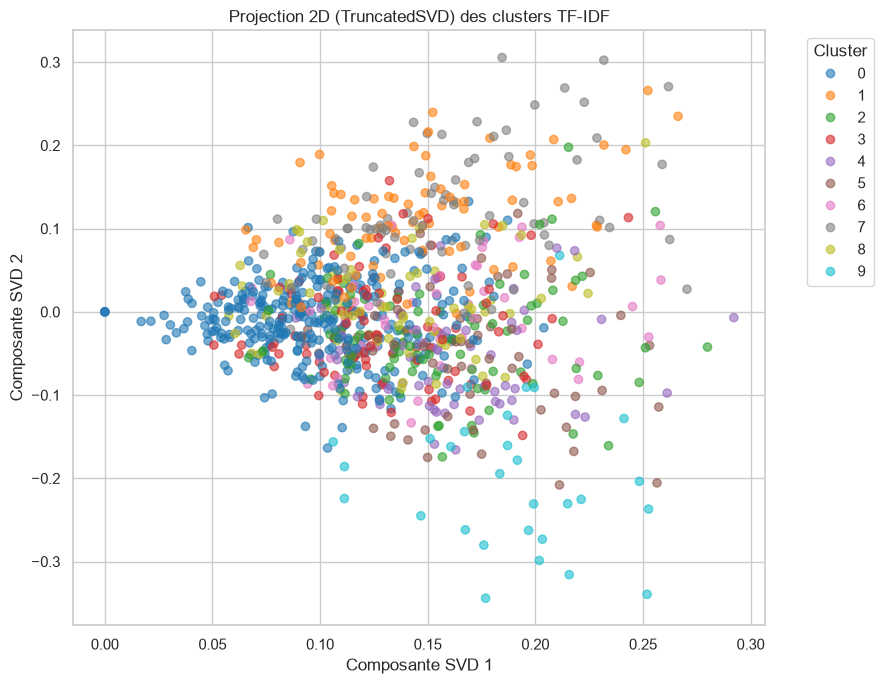

In [14]:
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_svd_2d = svd_2d.fit_transform(X_tfidf)

explained = svd_2d.explained_variance_ratio_.sum()
print(f"Variance expliquée par les 2 composantes SVD : {explained:.1%}")

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_svd_2d[:, 0], X_svd_2d[:, 1], c=df["cluster_text"], cmap="tab10", alpha=0.6)
plt.title("Projection 2D (TruncatedSVD) des clusters TF-IDF")
plt.xlabel("Composante SVD 1")
plt.ylabel("Composante SVD 2")
plt.legend(*scatter.legend_elements(), title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 4. Bonus — Clustering combiné (structuré + texte)



In [15]:
svd_struct_combo = TruncatedSVD(n_components=20, random_state=42)
X_tfidf_reduced = svd_struct_combo.fit_transform(X_tfidf)
print(f"Variance expliquée par les 20 composantes SVD (pour la combinaison) : {svd_struct_combo.explained_variance_ratio_.sum():.1%}")

X_combined = np.hstack([X_struct, X_tfidf_reduced])
X_combined = StandardScaler().fit_transform(X_combined)

print(f"Dimensions de la matrice combinée : {X_combined.shape}")


Variance expliquée par les 20 composantes SVD (pour la combinaison) : 10.6%
Dimensions de la matrice combinée : (931, 40)


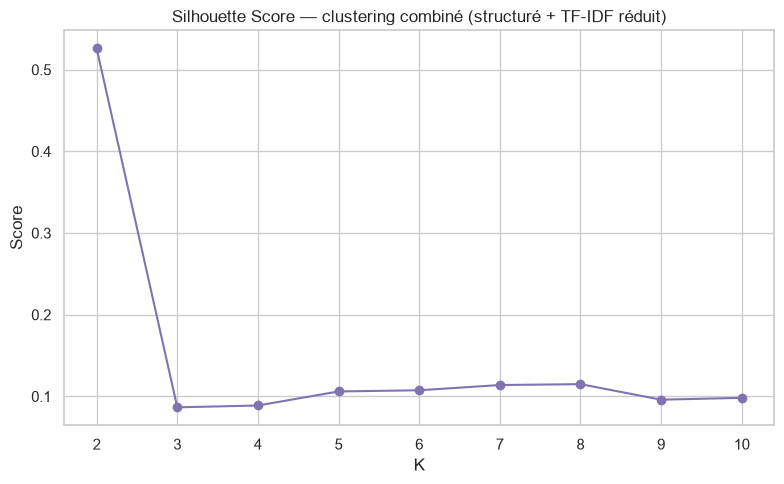

Meilleur K (silhouette, combiné) : 2


In [16]:
k_range_combo = range(2, 11)
silhouette_scores_combo = []

for k in k_range_combo:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_combined)
    silhouette_scores_combo.append(silhouette_score(X_combined, labels))

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_combo), silhouette_scores_combo, marker="o", color="#8172B2")
plt.title("Silhouette Score — clustering combiné (structuré + TF-IDF réduit)")
plt.xlabel("K")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

best_k_combo = list(k_range_combo)[int(np.argmax(silhouette_scores_combo))]
print(f"Meilleur K (silhouette, combiné) : {best_k_combo}")
